# Praktikum Text Clustering

**Nama** : Christina Adelia Sitinjak  
**NIM** : 42324056 

Text clustering adalah proses mengelompokkan teks ke dalam beberapa klaster berdasarkan kemiripan isinya, tanpa memakai label. Pada praktikum ini teks yang dikelompokkan adalah sinopsis (overview) film dari dataset TMDB 5000 Movies. Prosesnya mulai dari membersihkan teks, mengubah teks menjadi angka dengan TF-IDF, mengelompokkan dengan K-Means, lalu menampilkan hasilnya dalam grafik dua dimensi memakai PCA.

In [ ]:
# Import library
import pandas as pd
import numpy as np
import re
import string
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\sitin_veptvir\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\sitin_veptvir\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

#### Penjelasan:
Kode di atas untuk meng-import semua library yang dibutuhkan. `pandas` dan `numpy` dipakai untuk mengolah data, `re` dan `string` untuk membersihkan teks, `word_tokenize` untuk memecah kalimat menjadi kata, dan `WordNetLemmatizer` untuk mengubah kata ke bentuk dasarnya. Dari scikit-learn dipakai `TfidfVectorizer` untuk mengubah teks menjadi angka, `KMeans` untuk mengelompokkan, dan `PCA` untuk mengecilkan dimensi data supaya bisa digambar. `matplotlib` dipakai untuk membuat grafiknya.

In [9]:
# Load dataset
file_path = "tmdb_5000_movies.csv.gz"
df = pd.read_csv(file_path)

# Hanya mengambil kolom overview untuk klasterisasi
df = df.rename(columns={'overview': 'text'})

df = df.dropna(subset=['text']).reset_index(drop=True)

#### Penjelasan:
Kode di atas untuk membuka dataset film dan menyiapkan kolom teks yang akan dikelompokkan. Dataset ini berformat `.csv.gz`, yaitu file CSV yang dikompres dengan gzip supaya ukurannya lebih kecil. File ini tidak perlu diekstrak, karena `pd.read_csv` bisa langsung membacanya.

Di modul, bagian ini membaca `Text.csv` dan mengganti nama kolom `Message` menjadi `text`. Karena dataset yang dipakai sekarang adalah data film, kolom yang diambil adalah `overview` (sinopsis film), lalu namanya diganti menjadi `text` supaya kode di langkah berikutnya bisa dipakai tanpa perubahan.

Baris `dropna` ditambahkan untuk membuang film yang kolom overview-nya kosong. Ada 3 film yang overview-nya kosong, dan teks kosong dibaca sebagai `float` oleh pandas sehingga membuat fungsi `clean_text` error saat memanggil `.lower()`. Setelah film tersebut dibuang, tersisa 4800 film. `reset_index(drop=True)` dipakai untuk merapikan kembali nomor index supaya urut dari 0 setelah baris-baris dibuang.

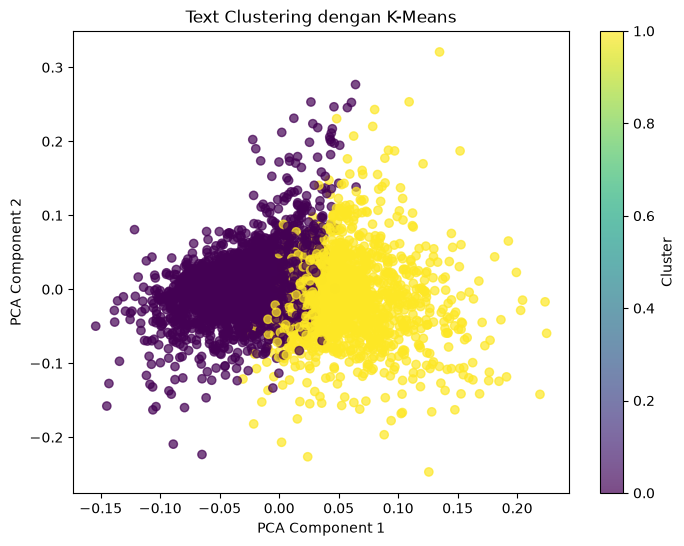

In [10]:
# Inisialisasi lemmatizer
lemmatizer = WordNetLemmatizer()

# Fungsi preprocessing teks
def clean_text(text):
    text = text.lower() # Lowercasing
    text = re.sub(r'\d+', '', text) # Hapus angka
    text = text.translate(str.maketrans('', '', string.punctuation)) # Hapus tanda baca
    words = word_tokenize(text) # Tokenisasi
    words = [lemmatizer.lemmatize(word) for word in words] # Lemmatization
    return ' '.join(words)

# Terapkan preprocessing ke teks
df['clean_text'] = df['text'].apply(clean_text)

# Konversi teks ke vektor TF-IDF
vectorizer = TfidfVectorizer(stop_words='english')      # Menggunakan stopwords dari sklearn
X = vectorizer.fit_transform(df['clean_text'])

# Tentukan jumlah klaster
num_clusters = 2
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X)

# Visualisasi dengan PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X.toarray())

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['cluster'], cmap='viridis', alpha=0.7)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Text Clustering dengan K-Means")
plt.colorbar(label='Cluster')
plt.show()

#### Penjelasan:
Kode di atas untuk menjalankan seluruh proses text clustering, mulai dari membersihkan teks sampai menampilkan hasil klasternya dalam grafik. Kodenya panjang, jadi kita bahas per bagian.

Bagian pertama adalah membersihkan teks lewat fungsi `clean_text`. Teks diubah menjadi huruf kecil semua, angka dan tanda baca dihapus, lalu kalimat dipecah menjadi kata-kata (tokenisasi). Setiap kata kemudian diubah ke bentuk dasarnya dengan lemmatization, misalnya "lives" menjadi "life", dan kata-katanya digabung lagi menjadi satu kalimat. Hasilnya disimpan di kolom baru `clean_text`. Berbeda dari praktikum Text Classification kemarin, fungsi ini tidak membuang stopwords, karena pembuangan stopwords nanti dilakukan oleh TF-IDF.

Bagian kedua adalah mengubah teks menjadi angka dengan `TfidfVectorizer(stop_words='english')`. Komputer tidak bisa mengelompokkan teks secara langsung, jadi tiap sinopsis diubah menjadi deretan angka yang menunjukkan seberapa penting setiap kata di sinopsis itu. Parameter `stop_words='english'` membuang kata-kata umum bahasa Inggris seperti "the" dan "and". Hasilnya `X` adalah tabel besar dengan satu baris untuk tiap film dan satu kolom untuk tiap kata unik.

Bagian ketiga adalah pengelompokan dengan K-Means. Nilai `num_clusters = 2` berarti film dibagi menjadi 2 klaster. `random_state=42` membuat hasilnya konsisten setiap kali dijalankan, dan `n_init=10` membuat K-Means dijalankan 10 kali dengan titik awal berbeda lalu dipilih hasil yang terbaik. `fit_predict(X)` melatih model sekaligus menentukan klaster tiap film, dan hasilnya disimpan di kolom `cluster` (bernilai 0 atau 1).

Bagian keempat adalah visualisasi. Tabel TF-IDF punya ribuan kolom, sehingga tidak mungkin digambar langsung. Karena itu dipakai PCA untuk meringkasnya menjadi 2 komponen saja, yaitu `X_pca`. `X.toarray()` dipakai karena PCA membutuhkan tabel penuh, sedangkan hasil TF-IDF disimpan dalam bentuk hemat memori. Setelah itu `plt.scatter` menggambar setiap film sebagai satu titik, dengan warna yang berbeda untuk tiap klaster, dan `plt.colorbar` menampilkan keterangan warnanya.

Cara membaca grafiknya, satu titik mewakili satu film, dan warna titik menunjukkan klasternya. Film dengan sinopsis yang mirip akan berdekatan dan berwarna sama. PCA hanya dipakai untuk menggambar, sedangkan pengelompokan sebenarnya dilakukan pada data TF-IDF yang asli, jadi bisa saja ada titik berbeda warna yang terlihat saling menumpuk di grafik.

Sel ini bisa berjalan agak lama karena ada ribuan sinopsis yang diproses satu per satu.